**Step 1: Set Up Colab and check the GPU**

Training the patch means running ResNet forwards and backwards hundreds of times. On a GPU that takes minutes; on a CPU it would be painfully slow. The T4 is the GPU the free tier gives you.

In [ ]:
import  torch
#PyTorch is a foundational, general-purpose deep learning and tensor computation framework.
#provides the core engine for building, training, and running neural networks, handling multi-dimensional array math (tensors), and performing automatic differentiation

import torchvision
#a specialised, domain-specific companion library built on top of PyTorch.
#focuses exclusively on computer-vision tasks, provides us with ready-to-use tools:
  #popular vision datasets and loaders (e.g., ImageNet and CIFAR-10),
  #pre-trained model architectures and weights (e.g., ResNet, EfficientNet),
  #image and video transformations and data augmentations (e.g., resizing, cropping, flipping))

print("PyTorch version:", torch.__version__)
print("torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

if device == "cuda":
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
torchvision version: 0.26.0+cu130
GPU available: True
Using device: cuda
GPU name: Tesla T4


**Step 2: Load the model and the images**

We use ResNet-50 pretrained on ImageNet (ImageNet is a massive dataset/benchmark and ResNet is a specific neural network architecture trained often on that dataset)

We use Imagenette (made by fast.ai) a free 10-class subset of ImageNet.

Imagenette is ideal because its 10 classes are real ImageNet classes, so the pretrained ResNet can already classify them.

The we measure exactly how much the patch breaks it.

**Step 2a. Download the dataset:**

The ***!*** prefix runs a shell command on the Colab machine instead of Python.

***wget -q*** downloads the file quietly (no progress spam).

The download is about 340 MB. The ***320*** means images are resized so their shorter side is 320 pixels, which is plenty for ResNet’s 224×224 input.

***tar -xzf*** unpacks the compressed archive into a folder.

***ls*** lists the folder. You should see **train, val** and a CSV file.


In [ ]:
# "!" runs a shell command on the Colab machine instead of Python.
# Download Imagenette (10-class ImageNet subset, shorter image side = 320 px, ~340 MB).
# wget = download files and mirror entire websites via HTTPS, HTTP, and FTP protocols
# -q = quiet mode, no progress output.
!wget -q https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz

# tar = bundle multiple files and directories into a single archive file
# Unpack the compressed archive: x = extract, z = gzip-compressed, f = from this file.
!tar -xzf imagenette2-320.tgz

# List the unpacked folder. Expect: train, val, and a CSV file.
!ls imagenette2-320

noisy_imagenette.csv  train  val


**Step 2b. Load ResNet-50**

Loading the weights:
*   ***ResNet50_Weights.IMAGENET1K_V1*** selects the pretrained weights: the parameters learned from training on ImageNet’s 1,000 classes. ***resnet50(weights=weights)*** builds the network and downloads those weights.
*   ***categories*** is the list of 1,000 class names, so index 0 is “tench”, and so on. We’ll use it to turn the model’s numeric outputs into readable labels.

**A normalised image** is an image whose pixel intensity values, dimensions, or spatial positions have been mathematically adjusted to fit a standard, consistent range or common statistical distribution. Changes the range of pixel values (e.g., scaling raw grayscale values from 0–255 down to a standard range of 0 to 1 or -1 to 1) to fix poor contrast, remove glare, or match a baseline brightness.

**Standard Range (0-255):**

0 represents pure black no light/intensity

255 represents pure white maximum light/intensity

Numbers in between represent various shades of grey

For a full-colour image, each pixel holds three of these numbers - one for Red, Green, Blue (RGB). E.g., a pixel value of (255, 0, 0) is pure red.


**Normalised Ranges:**

*0 to 1 range:* divide every pixel value by 255.

0 stays 0.0 (black)

127 becomes roughly 0.5 (grey)

255 becomes 1.0 (white)

*-1 to 1 range:* You scale the numbers further so that the "middle" or average value sits at 0.0, with darker pixels going negative and lighter pixels going positive.


Computers handle floating-point math (decimal numbers between 0 and 1) much better during complex calculations. If an AI model tries to multiply giant numbers like 255 over and over again through millions of pixels, the math quickly blows up and causes errors. Scaling them down keeps the numbers stable.


**The normalisation wrapper.** This is an important design decision, so here’s the intuition. ResNet was trained on images that were normalised: each colour channel had the ImageNet mean subtracted and was divided by the standard deviation. Normally you’d do that inside the data-loading transforms. For a patch attack, though, we want our images and patch to stay in pixel space, with values between 0 and 1 like a real image. That way, clamping the patch to [0, 1] means “a valid, printable colour”. So we keep the data in pixel space and move the normalisation inside the model.

*   ***class NormalisedModel(nn.Module)*** defines our own model that wraps ResNet. Every PyTorch model is a subclass of ***nn.Module***.
*   ***__init__*** runs once when the wrapper is created. It stores ResNet and the mean and standard deviation values.
*   ***register_buffer*** stores a tensor that belongs to the model but isn’t trainable. The benefit is that ***.to(device)*** moves it to the GPU along with the model.
*   ***.view(1, 3, 1, 1)*** reshapes the 3 numbers so they line up with the image tensor shape ***(batch, channels, height, width)***. PyTorch then broadcasts them: the same per-channel value is applied to every pixel of every image.
*   forward defines what happens when you call ***model(x)***: normalise, then run ResNet.


**Freezing the model:**
*  ***.to(device)*** moves the model to the GPU.
*   ***.eval()*** puts the model in evaluation mode. ResNet contains batch-normalisation layers, which behave differently in training mode (they’d use statistics from our batch, including the patch). In eval mode they use the fixed statistics learned during training, which is how the model behaves when deployed.
*   ***requires_grad_(False)*** on every parameter *freezes the weights*. In this exercise we never change the model; the only thing we train is the patch. Freezing also saves memory, since PyTorch won’t store gradients for 25 million weights.

if **requires_grad(True)** then it would actively track all operations performed on that parameter so it can calculate gradients (derivatives) during the backward pass (loss.backward())

if **requires_grad(False)** then PyTorch stops tracking operations foro that parameter, meaning no gradient will be calculated for it.





In [ ]:
import torch.nn as nn                                         # nn = PyTorch's neural-network building blocks
from torchvision.models import resnet50, ResNet50_Weights     # the ResNet-50 architecture and its pretrained weights

# Pick the weights learned on ImageNet's 1,000 classes.
weights = ResNet50_Weights.IMAGENET1K_V1

# Build ResNet-50 and load those pretrained weights (downloads them the first time).
base_model = resnet50(weights=weights)

# List of the 1,000 class names, e.g. categories[0] = "tench". Used to turn class numbers into readable labels.
categories = weights.meta["categories"]


# A wrapper that does ImageNet normalisation INSIDE the model,
# so our images and patch can stay in pixel space [0, 1].
class NormalisedModel(nn.Module):                 # every PyTorch model is a subclass of nn.Module

    def __init__(self, model):                    # runs once, when the wrapper is created
        super().__init__()                        # sets up nn.Module's internal machinery
        #init stores ResNet and the mean and standard deviation values
        self.model = model                        # store the ResNet we're wrapping

        # ImageNet per-channel mean and std (R, G, B), reshaped to (1, 3, 1, 1)
        # so they broadcast over a batch of images shaped (batch, 3, height, width).
        # register_buffer = part of the model, moves to GPU with it, but is NOT trained.
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):                         # runs every time we call model(x)
        # Normalise the pixel-space images, then pass them through ResNet.
        # Output: 1,000 scores (logits) per image, one per ImageNet class.
        return self.model((x - self.mean) / self.std)


# Wrap ResNet, move it to the GPU, and switch to evaluation mode
# (batch-norm layers use their fixed learned statistics, as in deployment).
model = NormalisedModel(base_model).to(device).eval()

# Freeze every weight: we only ever train the patch, never the model.
# Also saves memory, because no gradients are stored for the model's ~25M weights.
for p in model.parameters():
    p.requires_grad_(False)

print("Model loaded. Number of ImageNet classes:", len(categories))   # expect 1000

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 202MB/s]


Model loaded. Number of ImageNet classes: 1000


**Step 2c: Load the Images**

**The transform** is the preprocessing applied to every image as it’s loaded:
*   ***Resize(256)*** scales the image so its shorter side is 256 pixels.
(shorter side of an image refers strictly to whichever of its two main dimensions—the width or the height—has the lower pixel count. e.g., In landscape image: heighter is shorter side. In portrait image: the width is shorter side.)
*   ***CenterCrop(224)*** cuts out the central 224×224 square, the input size ResNet expects. These two steps are the standard ImageNet evaluation preprocessing.
*   ***ToTensor()*** converts the image into a PyTorch tensor of shape ***(3, 224, 224)*** with values in ***[0, 1]***. There’s no ***Normalize*** here, on purpose, because the wrapper in 2b handles it.


0D Scalar: A single number (e.g., a pixel value like 255)

1D Vector: A list of numbers (e.g., a 1D pixel array [255, 0, 0])

2D Matrix: A flat grid / grayscale image (Height × Width)

3D Tensor: A single colour image (Height × Width × RGB Channels)

4D Tensor: A batch of colour images (Batch Size × Height × Width × Channels)



**The datasets**:
*   ***ImageFolder*** reads a folder where each subfolder is one class. Imagenette’s subfolders are named by ImageNet IDs (e.g. **n01440764**), and ***ImageFolder*** numbers them 0–9 in sorted order.
*   **imagenet_idx** translates those 0–9 labels into ResNet’s 1,000-class numbering. For example, Imagenette label 0 (“tench”) is ImageNet class 0, and Imagenette label 1 (“English springer”) is ImageNet class 217. The print at the end checks that this mapping is correct.

**Train and Validation split**:
*   We train the patch on **training images** and evaluate it on **validation images** it has never seen. A good patch has to be *universal*, meaning it works on new images, not just the ones it was optimised on.
*   ***randperm*** shuffles the training indices and we take 2,000 of them, which is enough to learn a patch and keeps each training pass fast. ***manual_seed(0)*** makes the shuffle *reproducible*: same images every run, which matters for comparing the two losses in step 7.

**DataLoaders feed images to the GPU in batches:**
*   **batch_size=32** means 32 images per step. **shuffle=True** for training gives the patch a different mix of images each pass. Validation doesn’t need shuffling.
*   **num_workers=2** loads the next batch in the background while the GPU works on the current one.










In [ ]:
from torchvision import datasets, transforms           # dataset readers and image preprocessing
from torch.utils.data import DataLoader, Subset        # DataLoader = batches data; Subset = picks some images from a dataset

# Preprocessing applied to every image as it's loaded.
transform = transforms.Compose([
    transforms.Resize(256),        # scale so the shorter side is 256 px
    transforms.CenterCrop(224),    # cut out the central 224x224 square (ResNet's input size)
    transforms.ToTensor(),         # convert to a tensor of shape (3, 224, 224) with values in [0, 1]
    # No Normalize here, on purpose: NormalisedModel does it inside the model.
])

# ImageFolder treats each subfolder as one class and numbers them 0-9 in sorted folder-name order.
train_set = datasets.ImageFolder("imagenette2-320/train", transform=transform)
val_set = datasets.ImageFolder("imagenette2-320/val", transform=transform)

# Translate Imagenette labels (0-9) into ResNet's ImageNet class numbers (0-999).
# e.g. Imagenette label 0 -> ImageNet 0 (tench), label 1 -> ImageNet 217 (English springer).
imagenet_idx = torch.tensor([0, 217, 482, 491, 497, 566, 569, 571, 574, 701])


#ImageNet has 1000 classes (over 1.2 million images total)
#Imagenette has 10 classes (about 9469 training images and about 3925 valdiation images)
# Random number generator with a fixed seed, so we pick the SAME 2,000 images every run (reproducibility).
g = torch.Generator().manual_seed(0)

# Shuffle all training-image indices, keep the first 2,000, and wrap them as a smaller dataset.
train_subset = Subset(train_set, torch.randperm(len(train_set), generator=g)[:2000].tolist())

# Training loader: batches of 32, reshuffled each pass, 2 background workers loading the next batch.
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=2)

# Validation loader: images the patch never trains on, used to test whether the patch generalises.
# No shuffling needed for evaluation.
val_loader = DataLoader(val_set, batch_size=64, shuffle=False, num_workers=2)

print("Imagenette folders:", train_set.classes)                    # the 10 ImageNet folder IDs
print("Training images used:", len(train_subset))                  # expect 2000
print("Validation images:", len(val_set))                          # expect 3925
print("Mapped to ImageNet classes:", [categories[i] for i in imagenet_idx])   # checks the label mapping is right

Imagenette folders: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
Training images used: 2000
Validation images: 3925
Mapped to ImageNet classes: ['tench', 'English springer', 'cassette player', 'chain saw', 'church', 'French horn', 'garbage truck', 'gas pump', 'golf ball', 'parachute']


**Step 2d: Sanity check: look at the data**

*   ***next(iter(val_loader))*** takes one batch from the loader. ***images.shape*** should be ***[64, 3, 224, 224]***: 64 images, 3 colour channels, 224×224 pixels. This (batch, channel, height, width) layout is the standard PyTorch image format, and you’ll see it in every vision paper’s code.
*   The pixel range should be roughly 0 to 1, confirming we’re in pixel space.
*   **samples** picks every 400th validation image so we get several different classes (they’re stored in class order).
*   ***.permute(1, 2, 0)*** reorders the tensor to ***(height, width, channel)***, which is the layout matplotlib expects for displaying images.
*   Each image is titled with its true ImageNet class name.



Batch shape: torch.Size([64, 3, 224, 224])
Pixel range: 0.0 to 1.0


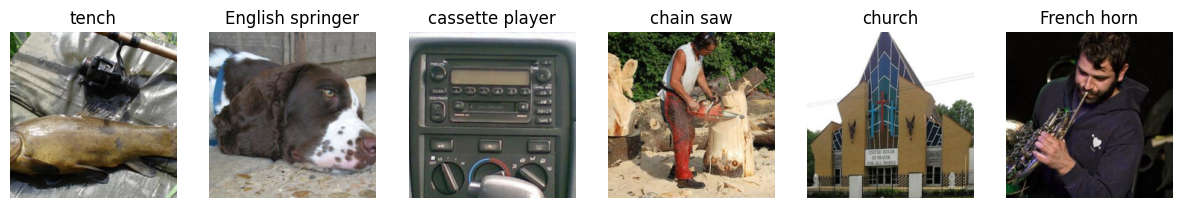

In [ ]:
import matplotlib.pyplot as plt     # plotting library, used here to display images

# Take one batch from the validation loader.
images, labels = next(iter(val_loader))

# Expect [64, 3, 224, 224] = (batch, channels, height, width), the standard PyTorch image layout.
print("Batch shape:", images.shape)

# Expect roughly 0 to 1, confirming the images are in pixel space (not normalised).
print("Pixel range:", images.min().item(), "to", images.max().item())

# Pick every 400th validation image, so we see several classes (images are stored in class order).
samples = [val_set[i] for i in range(0, len(val_set), 400)][:6]

# Create a row of 6 empty plots.
fig, axes = plt.subplots(1, 6, figsize=(15, 3))

for ax, (img, label) in zip(axes, samples):       # pair each plot with one (image, label)
    ax.imshow(img.permute(1, 2, 0))               # reorder (3, H, W) -> (H, W, 3), the layout matplotlib expects
    ax.set_title(categories[imagenet_idx[label]]) # title = the true ImageNet class name
    ax.axis("off")                                # hide the axis ticks

plt.show()                                        # display the figure

**Step 3: Measure clean accuracy (the baseline)**

**What and why.** Before attacking the model, we need to know how well it performs without a patch. Every attack result is stated relative to this: “the patch dropped accuracy from X% to Y%”. Without a baseline, the attacked number means nothing.

We’ll write two functions:

**evaluate** gives one number: the percentage of validation images classified correctly.

**show_predictions** gives a picture: a few images, each with its true class, predicted class and confidence.

Both get reused in step 6 to measure the patch, so they’re written with that in mind.


**3a. evaluate: the accuracy function**

**The flow.** For every batch of validation images, the function does the following:

1.   Move the images to the GPU.
2.   Convert the true labels from Imagenette numbering (0–9) to ImageNet numbering (0–999), so they match the model’s outputs.
3.   Optionally modify the images. Nothing happens now; in step 6 this is where the patch gets pasted on.
4.   Run the model to get 1,000 scores per image.
5.   Pick the highest score as the prediction.
6.   Compare predictions with the true labels and count the correct ones.

After all batches: accuracy = correct ÷ total.

In [ ]:
# Decorator: turns off gradient tracking for everything inside this function.
# We're only measuring, not training, so this saves memory and runs faster.
@torch.no_grad()
def evaluate(model, loader, transform_fn=None):
    correct = 0                                    # running count of correct predictions
    total = 0                                      # running count of images seen

    for images, labels in loader:                  # the loader hands us one batch at a time
        images = images.to(device)                 # move the batch of images to the GPU

        # Convert Imagenette labels (0-9) into ImageNet class numbers (0-999).
        # Indexing imagenet_idx with the whole label tensor converts all labels in one go.
        targets = imagenet_idx.to(device)[labels.to(device)]

        # Optional slot for modifying the images before the model sees them.
        # None for now (clean images); in step 6 it will paste the patch on.
        if transform_fn is not None:
            images = transform_fn(images)

        logits = model(images)                     # raw scores, shape (batch, 1000): one per ImageNet class
        preds = logits.argmax(dim=1)               # for each image, the class with the highest score

        correct += (preds == targets).sum().item() # count correct predictions in this batch
        total += labels.size(0)                    # number of images in this batch

    return correct / total                         # fraction correct, e.g. 0.87


clean_acc = evaluate(model, val_loader)            # run it on all 3,925 validation images
print(f"Clean accuracy: {clean_acc:.2%}")          # print as a percentage with 2 decimal places

Clean accuracy: 84.54%


**@torch.no_grad()**: Normally, PyTorch records every operation so it can compute gradients later (that’s how training works). Here we’re only measuring, so recording would waste memory. This decorator switches recording off for the whole function. In step 5, when we train the patch, we’ll need gradients, so the training loop won’t have this.

**for images, labels in loader**: The DataLoader from 2c splits the 3,925 validation images into batches of 64. Each pass of the loop gives you a tensor of 64 images, shape (64, 3, 224, 224), and their 64 labels. The last batch is smaller, because 3,925 isn’t a multiple of 64. That’s why we count labels.size(0) instead of assuming 64.

**The label conversion**: **imagenet_idx** is the lookup table [0, 217, 482, …]. Indexing a tensor with another tensor looks up every entry at once. For example:

labels               = [0, 1, 1, 3]

imagenet_idx[labels] = [0, 217, 217, 491]   → tench, springer, springer, chain saw

We need this because the model answers in ImageNet numbering, so the true labels must be in the same numbering to compare them. Both tensors are moved to the GPU because PyTorch can’t combine tensors on different devices.

**transform_fn**: This is a function passed in as an argument. Right now we pass nothing, so the images go in clean. In step 6 we’ll pass the “apply patch” function, and the exact same **evaluate** code then measures attacked accuracy. Writing it once keeps the clean and attacked measurements identical in every other respect, which makes the comparison fair.

**logits** and **argmax**: The model outputs 1,000 raw scores per image, called logits. the model gives a score for each class, to predict which class the image most likely belongs to. The highest score is the prediction. With 4 classes instead of 1,000, the idea looks like this:

logits for one image = [2.1, 0.3, 5.7, -1.0]

argmax               = 2   → the model predicts class 2 (each index stands for a class, so index 2 means "class 2")

**dim=1** means “take the max across the class dimension”, once per image. The model chooses from all 1,000 classes, not just our 10. That’s the realistic setting, and it means the patch can push an image towards any wrong class.

**Counting correct predictions:**

preds   = [0, 217, 999, 491]

targets = [0, 217, 217, 491]

preds == targets  → [True, True, False, True]

.sum()            → 3     (True counts as 1)

.item()           → 3 as a plain Python number

What to expect. A high accuracy, plausibly in the 80–90% range, because these are easy, distinct classes. The exact number doesn’t matter. What matters is that it’s high, so the attack has something to break.


**3b. show_predictions: seeing what the model does**

**What and why.** A single accuracy number hides how the model behaves. This function shows a few images with the true class, the predicted class and the model’s confidence. In step 6 you’ll run it with the patch and see predictions flip from green to red.

**The flow:**
1.   Load the chosen images and stack them into one batch.
2.   Optionally modify them (the patch, later).
3.   Run the model and convert the scores into probabilities.
4.   For each image, take the top probability (confidence) and its class (prediction).
5.   Plot each image, titled with true class, predicted class and confidence: green if correct, red if wrong.

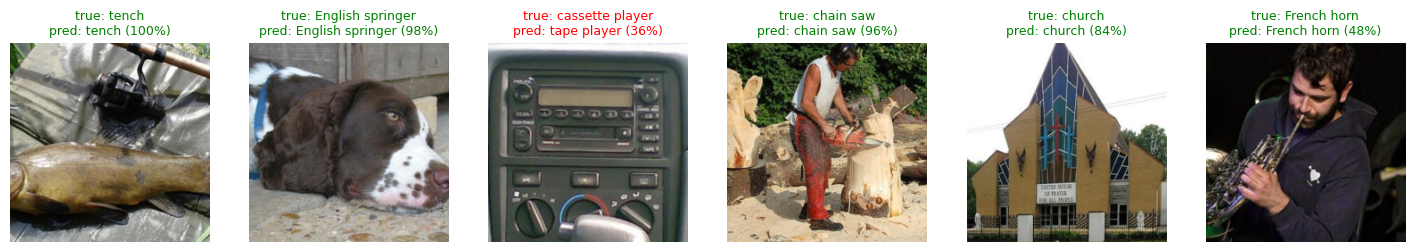

In [ ]:
@torch.no_grad()                                   # measuring only, no gradients
def show_predictions(model, dataset, indices, transform_fn=None):
    # dataset[i] returns (image, label). Take the image from each chosen index,
    # stack them into one batch of shape (N, 3, 224, 224), and move it to the GPU.
    imgs = torch.stack([dataset[i][0] for i in indices]).to(device)
    labels = torch.tensor([dataset[i][1] for i in indices])     # their Imagenette labels (0-9)

    if transform_fn is not None:                   # optional modification (the patch, later)
        imgs = transform_fn(imgs)

    # Softmax turns each image's 1,000 logits into probabilities that sum to 1.
    probs = model(imgs).softmax(dim=1)

    # For each image: the highest probability (confidence) and its class index (prediction).
    conf, preds = probs.max(dim=1)

    # A row of N empty plots, 3 inches wide each.
    fig, axes = plt.subplots(1, len(indices), figsize=(3 * len(indices), 3.5))

    # Walk through the plots and images together, one image per plot.
    for ax, img, p, c, l in zip(axes, imgs, preds, conf, labels):
        true_name = categories[imagenet_idx[l]]                 # true class name
        pred_name = categories[p]                               # predicted class name
        is_correct = p.item() == imagenet_idx[l].item()         # did the model get it right?

        ax.imshow(img.cpu().permute(1, 2, 0))      # back to the CPU, and (3, H, W) -> (H, W, 3) for matplotlib
        ax.set_title(f"true: {true_name}\npred: {pred_name} ({c.item():.0%})",
                     color="green" if is_correct else "red", fontsize=9)   # green = correct, red = wrong
        ax.axis("off")                             # hide axis ticks

    plt.show()


# The same six images as in 2d: every 400th validation image.
sample_idx = list(range(0, len(val_set), 400))[:6]
show_predictions(model, val_set, sample_idx)

**torch.stack**: Each dataset[i][0] is a single image of shape (3, 224, 224). stack places them on top of each other into one batch of shape (6, 3, 224, 224), because the model expects batches, even if it’s just six images.

**softmax**: This converts logits into probabilities between 0 and 1 that sum to 1. With 3 classes:

logits  = [2.0, 1.0, 0.0]

softmax = [0.67, 0.24, 0.09]   → 67% confident in class 0

Higher logits get a bigger share, and the gaps are exaggerated. We didn’t need softmax in evaluate, because the highest logit is always also the highest probability. Here we want a readable confidence percentage. Watch these numbers in step 6: a successful patch doesn’t just flip the prediction, it often makes the model confidently wrong.

**probs.max(dim=1)**: Unlike argmax, max returns two things: the highest value (the confidence) and where it is (the predicted class).

**zip(axes, imgs, preds, conf, labels)**: This walks through five lists in step. On the first loop you get the first plot, first image, first prediction, first confidence and first label, and so on. It’s a clean way to pair everything up.

**.cpu()**: Matplotlib can’t read tensors stored on the GPU, so we copy each image back to the CPU before plotting. **.permute(1, 2, 0)** reorders the shape from PyTorch’s (channels, height, width) to matplotlib’s (height, width, channels), as in 2d.

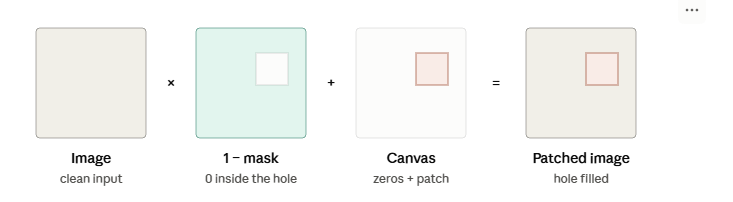



Why not just copy the patch’s pixels straight into the image? Because the patch has to stay connected to the computation graph. In step 5, PyTorch needs to trace the loss back through the patched image to the patch’s pixels to compute gradients. The multiply-and-add formula keeps that link intact.

**4a. Create the patch**

The flow:


1.   Fix the patch size
2.   Create a 3x50x50 tensor of random colours on the GPU
3.   Tell PyTorch to track gradients for it, since it's the one thing we'll train.
4.   Display it.


Patch shape: torch.Size([3, 50, 50])
Patch value range: 5.428108852356672e-05 to 0.9997397065162659
Tracks gradients: True


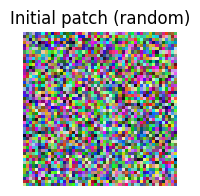

In [ ]:
PATCH_SIZE = 50        # patch is 50x50 pixels (~5% of a 224x224 image: 2,500 / 50,176)
IMAGE_SIZE = 224       # input image size, set by CenterCrop(224) in step 2c

# The patch: 3 colour channels x 50 x 50 pixels, random values in [0, 1] (random valid colours).
# requires_grad=True -> PyTorch tracks gradients for it, so we can train it in step 5.
# This is the ONLY trainable thing in the whole exercise; ResNet is frozen.
patch = torch.rand(3, PATCH_SIZE, PATCH_SIZE, device=device, requires_grad=True)

print("Patch shape:", patch.shape)                                   # expect [3, 50, 50]
print("Patch value range:", patch.min().item(), "to", patch.max().item())   # within [0, 1]
print("Tracks gradients:", patch.requires_grad)                      # expect True

# Display the starting patch.
# .detach() gives a copy that's disconnected from gradient tracking (needed before converting for plotting).
# .cpu() moves it off the GPU; .permute(1, 2, 0) reorders (3, H, W) -> (H, W, 3) for matplotlib.
plt.figure(figsize=(2, 2))
plt.imshow(patch.detach().cpu().permute(1, 2, 0))
plt.title("Initial patch (random)")
plt.axis("off")
plt.show()

**Patch size **: 50×50 covers about 5% of the image. That’s large enough to have a real effect, but small enough that most of the object is still visible, so if the model fails, it’s because of what the patch shows, not because it hides the object. You’ll see later that patch size is a key knob: bigger patches attack more easily. It’s one of the levers we can use to keep attacks constrained.

**torch.rand**: fills the tensor with random numbers between 0 and 1. Every pixel starts as a random valid colour, so the patch begins as coloured static.

**requires_grad=True**: is the important flag. It tells PyTorch: “this tensor is something I want to learn, so record how every result depends on it”. In step 2b we did the opposite for ResNet’s weights. That reversal is the core idea of this exercise. In normal training you update the model’s weights to fit the data; in an adversarial attack you freeze the model and update the input to break it.

**.detach()**: You can’t convert a gradient-tracked tensor to a plot directly, because PyTorch won’t let you leave the graph by accident. .detach() makes a copy without gradient tracking, which is safe for plotting. You’ll use it every time you display the patch.

**4b. The function that pastes the patch**

**The flow**: For each image in the batch:

1. Choose where the patch goes: a random top-left corner (x, y), or a fixed corner if we turn randomness off.
2. On the canvas, place the patch at (x, y).
3. On the mask, set the same 50×50 square to 1.

Then, for the whole batch at once, cut the hole and add the canvas.

In [ ]:
def apply_patch(images, patch, random_location=True):
    batch_size = images.size(0)                  # number of images in this batch

    canvas = torch.zeros_like(images)            # all zeros, same shape as the batch: (batch, 3, 224, 224)
    mask = torch.zeros_like(images)              # all zeros; we'll mark the patch area with 1s

    for i in range(batch_size):                  # each image gets its own patch position
        if random_location:
            # Random top-left corner. The largest valid value is 224 - 50 = 174,
            # so the patch always fits fully inside the image.
            # randint's upper bound is exclusive, hence the +1.
            x = torch.randint(0, IMAGE_SIZE - PATCH_SIZE + 1, (1,)).item()
            y = torch.randint(0, IMAGE_SIZE - PATCH_SIZE + 1, (1,)).item()
        else:
            # Fixed position: bottom-right corner (useful for consistent visual comparisons).
            x = IMAGE_SIZE - PATCH_SIZE
            y = IMAGE_SIZE - PATCH_SIZE

        # Place the patch on the canvas: image i, all 3 channels, rows y..y+50, columns x..x+50.
        canvas[i, :, y:y + PATCH_SIZE, x:x + PATCH_SIZE] = patch

        # Mark the same square in the mask with 1s.
        mask[i, :, y:y + PATCH_SIZE, x:x + PATCH_SIZE] = 1

    # Cut a hole in each image where the patch goes, then fill it with the patch.
    return images * (1 - mask) + canvas


# Quick test on one batch of validation images.
test_images, _ = next(iter(val_loader))          # "_" = we don't need the labels here
test_images = test_images.to(device)
patched = apply_patch(test_images, patch)

print("Input shape:", test_images.shape)          # expect [64, 3, 224, 224]
print("Output shape:", patched.shape)             # same shape: the patch doesn't change the image size
print("Output range:", patched.min().item(), "to", patched.max().item())   # still within [0, 1]
print("Connected to the patch's gradients:", patched.requires_grad)        # expect True

Input shape: torch.Size([64, 3, 224, 224])
Output shape: torch.Size([64, 3, 224, 224])
Output range: 0.0 to 1.0
Connected to the patch's gradients: True


**torch.zeros_like(images)**: creates an all-zero tensor with the same shape, data type and device as **images**. The canvas and mask must match the image batch exactly, or the multiply-and-add would fail.

**Slicing**: [i, :, y:y+50, x:x+50]. This picks out one region of the batch tensor, read left to right along the (batch, channel, height, width) layout:

- i selects image number i in the batch.
- : selects all 3 colour channels.
- y:y+50 selects 50 rows, starting at row y (height, measured from the top).
- x:x+50 selects 50 columns, starting at column x (width, measured from the left).

For example, with x = 100 and y = 20, the patch covers rows 20–69 and columns 100–149. Note that rows come before columns, which is why y comes before x. **Mixing them up is one of the most common bugs in image code.**

**The random range**: The top-left corner can go from 0 to 174 (224 − 50). Any further and the patch would hang off the edge. **torch.randint**’s upper limit is exclusive, so we write + 1 to make 174 itself possible.

**The final line**:
'images * (1 - mask) + canvas' is the formula from the diagram, done for all images at once.

Outside the patch area: image × 1 + 0 = the original image. Inside: image × 0 + patch = the patch. Because every operation is ordinary arithmetic involving the patch, PyTorch can trace gradients back to the patch’s pixels. That’s what the last print checks. **requires_grad: True** means the patched images are still connected to the patch.

**4c. Test the random patch: your first control**

Before training, measure what an untrained random patch does. If a trained patch drops accuracy to 10% but random noise of the same size drops it to 75%, then the training is responsible for the difference, not just the fact that part of the image is covered.

Clean accuracy:        84.54%
Random-patch accuracy: 81.86%


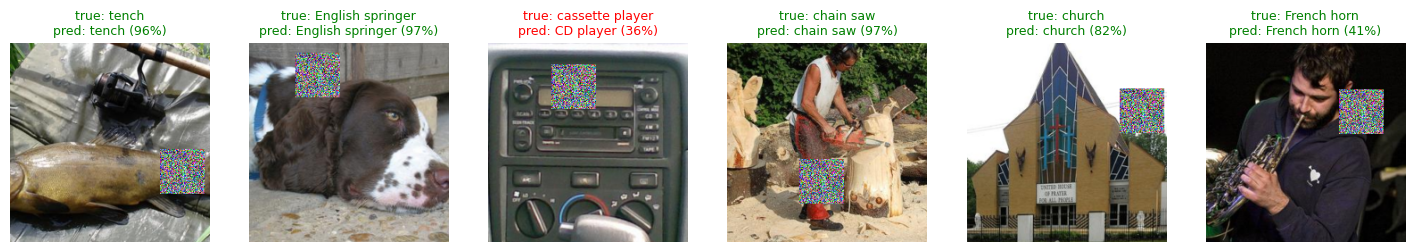

In [ ]:
# lambda = a tiny unnamed function. This one takes a batch of images and returns them with the patch pasted on.
# It's the transform_fn slot we built into evaluate() and show_predictions() in step 3.
add_random_patch = lambda imgs: apply_patch(imgs, patch)

# Accuracy with the untrained (random) patch at random positions on all validation images.
random_patch_acc = evaluate(model, val_loader, transform_fn=add_random_patch)
print(f"Clean accuracy:        {clean_acc:.2%}")
print(f"Random-patch accuracy: {random_patch_acc:.2%}")

# The same six images as before, now with the random patch.
show_predictions(model, val_set, sample_idx, transform_fn=add_random_patch)

**lambda** is a shortcut for writing a one-line function. **lambda imgs: apply_patch(imgs, patch)** means “a function that takes imgs and returns apply_patch(imgs, patch)”. It adapts apply_patch, which needs two arguments, into the one-argument shape that transform_fn expects.

**Reusing step 3’s functions**: The clean and random-patch measurements now go through exactly the same evaluate code. The only difference is the patch, which is what makes this a fair control.

**What to expect**: The random patch should cost only a few percentage points. Covering 5% of an image with static rarely confuses ResNet. The predictions on the six images should mostly stay green. Because the patch lands in a different random place each run, this number will wobble slightly if you rerun the cell. That’s normal.

**IMPORTANT NOTE:**
"Tracking gradients" means PyTorch **records every calculation that involves that tensor**, so that later it can work backwards and answer the question: **if I changed this value slightly, how much would the final result change?** That answer is the **gradient**.

You switch it on with **requires_grad=True**. From then on, PyTorch keeps a record, called the **computation graph**, of everything done to the tensor. When you call **.backward()** on the final result, PyTorch walks back through that record using the chain rule and stores the gradient in the tensor’s **.grad**.

**Why the patch needs it**: In step 5, the "result" is the loss, and the patch’s 7,500 pixel values (3 × 50 × 50) are the inputs. After **loss.backward()**, **patch.grad** holds one number per pixel: "nudge this pixel up and the loss goes up or down by this much". The optimiser uses those numbers to decide which way to move each pixel. Without tracking, **patch.grad** would be empty, and the optimiser would have nothing to go on.

In [ ]:
#IMPORTANT NOTE'S EXAMPLE:

x = torch.tensor(2.0, requires_grad=True)   # track gradients for x
y = 3 * x ** 2                              # PyTorch records: x -> square -> multiply by 3
y.backward()                                # work backwards: how does y change when x changes?
print(x.grad)                               # tensor(12.)

#By hand: y = 3x², so the gradient is dy/dx = 6x. At x = 2, that’s 12. PyTorch worked it out automatically because it recorded the calculation.

tensor(12.)


**The six images from Step 4c** show that random noise barely matters: the model is still confident on the clear images. Only the cassette player moved, from “tape player” to “CD player”, and it was already wrong. So far, covering 5% of the image does almost nothing. Step 5 is where that changes.

**Step 5: Train the patch (the attack)**

**What and why**: This is the core of the exercise. We’ll repeatedly show the model training images with the patch pasted on, measure how right the model still is, and nudge the patch’s pixels in whichever direction makes it less right. After a few hundred nudges, the noise turns into a pattern that ResNet finds overwhelmingly distracting.

This is the same machinery as normal neural-network training, with one switch: **the model is frozen and the input (the patch) is what gets trained**, and we push the loss up instead of down.

Here’s one training step as a picture. The forward pass goes left to right, and the gradients come back to update only the patch:

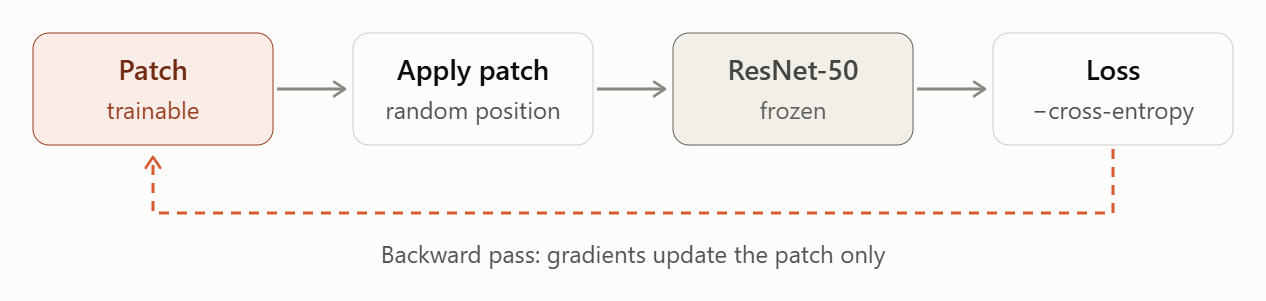

**The loss: what are we optimising?**

We use **cross-entropy**, the standard classification loss. For one image, it’s based on the probability the model gives to the **true** class:

**cross-entropy = −log(probability of the true class)**

- If the model is confident and right (true-class probability 0.9), the loss is −log(0.9) = 0.11, which is small.
- If the model is barely considering the true class (probability 0.1), the loss is −log(0.1) = 2.30, which is large.

Normal training *minimises* cross-entropy to make the model right. **We want the opposite: to drive the true-class probability down**, so we maximise cross-entropy. PyTorch optimisers only ever minimise, so we **minimise the negative cross-entropy** instead, which amounts to the same thing:

**loss = −cross_entropy**

This is an untargeted attack: we don’t care which wrong class the model picks, only that it isn’t the right one. A targeted attack would instead push every image towards one chosen class, like the famous “toaster” patch from Brown et al.

**5a. The training loop**

**The flow:**

1. Set up the optimiser, which handles the nudging, and tell it the patch is the only thing to update.
2. For each epoch/starting point (one full pass over the 2,000 training images), and for each batch of 32 images:
  - Paste the patch at random positions.
  - Run the frozen model and compute the loss.
  - Clear old gradients, compute new ones (backward), and update the patch (step).
  - Clamp the patch to 0–1, so it stays valid colours.
  - Record the loss and how many images were misclassified.
3. Print a summary at the end of each epoch.

In [ ]:
import torch.nn.functional as F        # F = PyTorch's functional toolbox; contains cross_entropy

# The optimiser decides how to change the patch, using its gradients.
# We pass ONLY [patch], so it's the only thing it will ever update. ResNet is frozen anyway.
# lr = learning rate = how big each nudge is (in pixel-value units, on a 0-1 scale).
optimizer = torch.optim.Adam([patch], lr=0.01)

NUM_EPOCHS = 5                         # 5 full passes over the 2,000 training images = ~315 updates
loss_history = []                      # loss after every update, for plotting the learning curve

for epoch in range(NUM_EPOCHS):
    epoch_loss = 0.0                   # summed loss over this epoch (for the average)
    fooled = 0                         # training images misclassified this epoch
    seen = 0                           # training images processed this epoch

    for images, labels in train_loader:                     # batches of 32 training images
        images = images.to(device)                          # move images to the GPU
        targets = imagenet_idx.to(device)[labels.to(device)]   # Imagenette labels (0-9) -> ImageNet labels (0-999)

        # Forward pass: paste the patch at random positions (EOT), then run the frozen model.
        patched = apply_patch(images, patch)
        logits = model(patched)                             # (32, 1000) class scores

        # Untargeted attack loss: NEGATIVE cross-entropy with the TRUE labels.
        # Minimising this = maximising cross-entropy = pushing the true class's probability down.
        loss = -F.cross_entropy(logits, targets)

        optimizer.zero_grad()          # wipe gradients from the previous step (PyTorch adds them up otherwise)
        loss.backward()                # compute d(loss)/d(patch pixel) for every patch pixel, via the chain rule
        optimizer.step()               # nudge every patch pixel in the direction that lowers the loss

        # Keep every pixel a valid colour in [0, 1].
        # no_grad: this is a correction, not part of the computation we want gradients for.
        # clamp_ (with underscore) = modify the patch in place, so it's still the same tensor the optimiser tracks.
        with torch.no_grad():
            patch.clamp_(0, 1)

        # Bookkeeping.
        loss_history.append(loss.item())                    # .item() = plain Python number
        epoch_loss += loss.item() * labels.size(0)          # weight by batch size (the last batch is smaller)
        fooled += (logits.argmax(dim=1) != targets).sum().item()   # wrong predictions in this batch
        seen += labels.size(0)

    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
          f"avg loss: {epoch_loss / seen:.3f} | "
          f"training images misclassified: {fooled / seen:.2%}")

Epoch 1/5 | avg loss: -0.832 | training images misclassified: 21.10%
Epoch 2/5 | avg loss: -6.639 | training images misclassified: 68.70%
Epoch 3/5 | avg loss: -18.088 | training images misclassified: 99.45%
Epoch 4/5 | avg loss: -20.937 | training images misclassified: 99.85%
Epoch 5/5 | avg loss: -22.096 | training images misclassified: 99.95%


**torch.optim.Adam([patch], lr=0.01)**: The optimiser is the part that actually changes the patch. **Adam** is the most common default. Compared with plain gradient descent, it adapts the step size for each pixel separately, which makes it robust without much tuning. The learning rate of 0.01 means each update moves a pixel by roughly 0.01 on the 0–1 colour scale. That’s small enough to be stable, and over hundreds of updates it adds up to big changes.

**Why there’s no *@torch.no_grad()* here**: In step 3 we turned gradient tracking off because we were only measuring. Here we need it: the whole point is to get gradients for the patch. The model is still in **.eval()** mode and frozen, so its weights don’t change, but gradients still flow through it back to the patch.

**F.cross_entropy(logits, targets)** does three things in one call: softmax over the 1,000 logits, picks out the true class’s probability for each image, then takes −log and averages over the batch. You give it raw logits, not probabilities, because it applies softmax itself.

**The three-line update: zero_grad, backward, step**:  This is the heart of every PyTorch training loop, so it’s worth knowing well.

**optimizer.zero_grad()**: PyTorch adds new gradients to old ones by default. Without this line, every step would also carry the gradients of all previous steps. So we wipe them first.
**loss.backward()**: this is **backpropagation**. PyTorch walks backwards from the loss through ResNet and through **apply_patch** to the patch, using the chain rule. The result is stored in **patch.grad**, a tensor the same shape as the patch (3×50×50). Each entry says *"if this pixel increased slightly, how would the loss change?"* Because ResNet is frozen, the patch is the only thing that receives a gradient.
**optimizer.step()**: Adam moves every pixel a small amount in the direction that lowers the loss. Because our loss is negative cross-entropy, lowering it means making the model more wrong.

**patch.clamp_(0, 1)**: The update can push pixels slightly below 0 or above 1, which aren’t real colours. Clamping snaps them back into range after every step. **This is the simplest version of a physical-realisability constraint**:  the printability constraint is the same idea taken further, restricting the patch to colours a printer can actually reproduce. The trailing underscore means "in place": it changes the existing tensor rather than creating a new one, so the optimiser keeps tracking the same patch.

**Random positions during training**: Every batch calls **apply_patch** with random positions, so each update teaches the patch to work wherever it lands. That’s the EOT idea in action. A patch trained at one fixed position would likely fail when moved.

**"Training images misclassified"**: This counts all wrong predictions, including the roughly 15% the model gets wrong even without a patch. Expect it to start around 15–20% and climb with each epoch. The proper measurement, on unseen validation images, comes in step 6.

**What to expect**: Each epoch takes about 20–40 seconds, so roughly 2–4 minutes in total. The average loss should become more negative every epoch (for example −2, then −5, then −8). It has no lower limit, because cross-entropy can keep growing as the true class’s probability approaches zero. The misclassification rate should rise substantially. Exactly how far depends on the run.

**5b. Look at the learning curve and the trained patch, and save it**

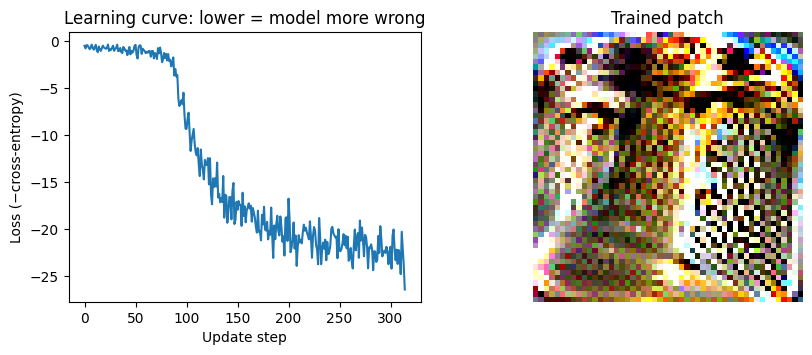

Saved trained patch to patch_ce.pt


In [ ]:
# Two plots side by side: the loss over training, and the trained patch.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

ax1.plot(loss_history)                         # loss after every update
ax1.set_xlabel("Update step")
ax1.set_ylabel("Loss (−cross-entropy)")
ax1.set_title("Learning curve: lower = model more wrong")

ax2.imshow(patch.detach().cpu().permute(1, 2, 0))   # detach -> CPU -> (H, W, 3), as in 4a
ax2.set_title("Trained patch")
ax2.axis("off")

plt.show()

# Save the trained patch to a file, so it survives if Colab disconnects
# and so we can compare it with the step-7 patch later.
torch.save(patch.detach().cpu(), "patch_ce.pt")
print("Saved trained patch to patch_ce.pt")

**The learning curve** plots the loss after each of the ~315 updates. You want a downward trend: noisy, because every batch is different and the patch positions are random, but clearly going down. A flat line would mean the patch isn’t learning, which usually points to a bug, such as the patch not being connected to the graph.

**The trained patch** will look nothing like the random static it started as. Expect large swirls or object-like textures. Patches often develop features the model strongly associates with some class, which overwhelms the real object.

**torch.save** writes the tensor to a file on the Colab machine.

**OUTPUT FROM STEP 5B:**

That is a very strong attack. Training-image misclassification went from 23% in epoch 1 to 99.85% by epoch 5. Here's how to read the plots.

**The learning curve has three phases:**

1. **Steps 0–60**: a plateau. The patch is still mostly noise and the gradients are only slowly finding a useful direction.
2. **Steps 60–150**: a sharp drop. The patch has found a pattern the model reacts to strongly, and each update reinforces it. This “slow start, then sudden take-off” shape is very common in patch attacks.
3. **Steps 150–315**: flattening. Nearly every image is already fooled, so there’s little left to gain.

**What a loss of about −20 means**: Cross-entropy is −log(true-class probability). A cross-entropy of 20 means the true class gets a probability of about e⁻²⁰, roughly 0.000000002. The model isn’t just wrong; it has essentially ruled out the correct answer.

**The patch** has gone from uniform static to structured blobs, dark curves and high-contrast textures. ResNet sees something in it that outweighs the real object.

An unconstrained patch saturates at about 100% success. For constrained attacks: a smaller patch, a printability constraint or a naturalness prior is needed to see this effect directly once you start shrinking PATCH_SIZE.

**Step 6: Evaluate the trained patch**

**What and why.** The 99.85% was measured on the training images the patch was optimised on. The real test is the validation images it has never seen. If the patch is genuinely universal, it should still work there. We’ll measure four things:

1. **Accuracy** with the trained patch, compared with clean and random patch.
2. **Attack success rate (ASR)**: of the images the model got right when clean, how many does the patch flip to wrong? This is the standard metric in attack papers. It’s cleaner than accuracy because it ignores images the model was already getting wrong.
3. **A fixed-position check**: does the patch work equally well in one corner as at random positions?
4. **What the model predicts instead**: does it scatter its wrong answers, or collapse onto one class?

**6a. Accuracy at random and fixed positions**

**The flow:**

Reuse ***evaluate*** from step 3, passing in the trained patch, once at random positions and once at a fixed position. Then print everything side by side.

In [ ]:
# The trained patch is still in the variable `patch` (training updated it in place).
add_trained_patch = lambda imgs: apply_patch(imgs, patch)                          # random positions
add_trained_patch_fixed = lambda imgs: apply_patch(imgs, patch, random_location=False)   # always bottom-right

trained_acc = evaluate(model, val_loader, transform_fn=add_trained_patch)
trained_acc_fixed = evaluate(model, val_loader, transform_fn=add_trained_patch_fixed)

print(f"Clean accuracy:                          {clean_acc:.2%}")
print(f"Random-patch accuracy (control):         {random_patch_acc:.2%}")
print(f"Trained-patch accuracy (random position): {trained_acc:.2%}")
print(f"Trained-patch accuracy (fixed position):  {trained_acc_fixed:.2%}")

Clean accuracy:                          84.54%
Random-patch accuracy (control):         81.86%
Trained-patch accuracy (random position): 0.15%
Trained-patch accuracy (fixed position):  4.41%


**Same evaluate, different patch.** Only the **transform_fn** changes between these rows. The images, the model and the counting are identical, so any difference in accuracy comes from the patch alone. That’s why we built **evaluate** with that slot back in step 3.

**Random vs fixed position.** The patch was trained at random positions, so it should work about equally well in the fixed corner. If the fixed-position accuracy were much worse than random (i.e. a higher accuracy, meaning the attack failed there), it would mean the patch only works in some places. A similar result for both confirms that the EOT-style training did its job.

**6b. Attack success rate**

**The flow:**

1. Write a function that collects the model’s prediction for every validation image, optionally with a patch.
2. Run it twice: clean, and with the trained patch.
3. Collect the true labels in the same order.
4. Among images the model got right when clean, count how many are wrong with the patch.

In [ ]:
@torch.no_grad()                                     # measuring only
def predicted_classes(model, loader, transform_fn=None):
    all_preds = []                                   # one tensor of predictions per batch
    for images, _ in loader:                         # labels not needed here
        images = images.to(device)
        if transform_fn is not None:                 # optional patch
            images = transform_fn(images)
        preds = model(images).argmax(dim=1)          # predicted ImageNet class for each image
        all_preds.append(preds.cpu())                # move to CPU and store
    return torch.cat(all_preds)                      # join the batches into one tensor of 3,925 predictions


# All validation labels, converted to ImageNet numbering, in the same order as the loader.
# This works because val_loader has shuffle=False, so the order is the same every time.
all_targets = torch.cat([imagenet_idx[labels] for _, labels in val_loader])

clean_preds = predicted_classes(model, val_loader)                              # no patch
patched_preds = predicted_classes(model, val_loader, add_trained_patch)        # trained patch, random positions

clean_correct = clean_preds == all_targets           # True where the model was right without the patch
flipped = clean_correct & (patched_preds != all_targets)   # right before AND wrong after = successfully attacked

asr = flipped.sum().item() / clean_correct.sum().item()
print(f"Images correct when clean:    {clean_correct.sum().item()} / {len(all_targets)}")
print(f"Of those, flipped by patch:   {flipped.sum().item()}")
print(f"Attack success rate (ASR):    {asr:.2%}")

Images correct when clean:    3318 / 3925
Of those, flipped by patch:   3314
Attack success rate (ASR):    99.88%


**Why ASR, and not just accuracy?** About 15% of images are wrong even without a patch. Accuracy mixes those in with images the patch actually broke. ASR only looks at the images the model could handle, and asks how many the attack took away. For example, if 3,318 images are correct when clean and the patch flips 3,300 of them, the ASR is 3,300 ÷ 3,318 = 99.5%.

**torch.cat**: The loader gives predictions in chunks of 64. **cat** joins those chunks end to end into one long tensor of 3,925 predictions, one per validation image.

**Why the order matters**: We compare **clean_preds, patched_preds** and **all_targets position** by position: entry 0 is the same image in all three. That only works because **val_loader** doesn’t shuffle. If it did, entry 0 would be a different image each time and the comparison would be meaningless. It’s a subtle kind of bug that produces numbers that look plausible but are wrong.

**&** is element-wise **AND** on True/False tensors. **clean_correct & (patched_preds != all_targets)** is True only where both conditions hold: right before and wrong after.

**6c. What does the model predict instead?**

In [ ]:
# Count how often each of the 1,000 classes is predicted with the patch.
# bincount: entry k = how many images were predicted as class k.
counts = torch.bincount(patched_preds, minlength=1000)

# The 5 most-predicted classes and their counts.
top_counts, top_classes = counts.topk(5)

print("Most common predictions with the trained patch:")
for c, n in zip(top_classes, top_counts):
    print(f"  {categories[c]:<25} {n.item():>5} images ({n.item() / len(patched_preds):.1%})")

Most common predictions with the trained patch:
  thimble                    3921 images (99.9%)
  golf ball                     3 images (0.1%)
  gas pump                      1 images (0.0%)
  tiger shark                   0 images (0.0%)
  goldfish                      0 images (0.0%)


**torch.bincount**: Given a list of class numbers, this counts how many times each number appears. For example, [3, 3, 7] gives a count of 2 at position 3 and 1 at position 7. **minlength=1000** makes sure there’s a slot for every ImageNet class, even ones never predicted.

**topk(5)** returns the 5 largest counts and which classes they belong to, like **max** but for the top 5.

**Why look at this?** We trained an *untargeted* attack, which only says "be wrong". Untargeted patches often still collapse onto one **dominant wrong class**, because the easiest way to make the model wrong everywhere is to make the patch look strongly like something. If one class takes most of the predictions, your patch has effectively become a targeted attack on its own, and that tells you what the dark curves and textures in your patch remind ResNet of.

**6d. See it on the six images**

These are the same six images we saw clean and with the random patch, so we can compare all three plots directly.

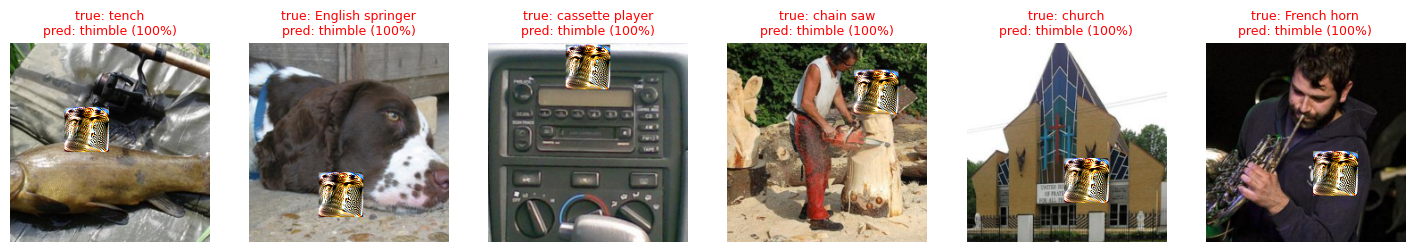

In [ ]:
show_predictions(model, val_set, sample_idx, transform_fn=add_trained_patch)

**Thimble wasn’t chosen by us; the optimisation found it.** An untargeted attack only says “make the model wrong”. It doesn’t care how. The easiest way to make ResNet wrong on every image is to make the patch look so strongly like one class that it overrides whatever else is in the picture. Three things probably made thimble the winner.

1. **The patch literally looks like a thimble.** Look at it on the images: a metallic gold and silver dome, covered in rows of small dimples. That’s a thimble’s defining texture. The optimiser pushed the pixels towards whatever maximises “thimble” evidence, and that is what it drew.

2. **ResNet relies heavily on texture.** CNNs trained on ImageNet are known to rely more on texture than on shape (Geirhos et al., 2019). A small patch of dimpled metal is extremely strong thimble evidence, even without the rest of the object.

3. **Small-object classes are easy targets**. Thimbles are photographed close up, so a 50×50 square can contain a whole convincing thimble. A 50×50 square can’t contain a whole church or garbage truck. Classes whose evidence fits in a small region are the natural attractors for small patches.

**Why one class took over completely:** It’s a snowball effect. Early in training, the random patch drifted slightly towards some class. Once a direction raised one class’s score across many images, every later update reinforced it. That’s the sharp drop we saw around steps 60–150 in the learning curve. With a different random starting patch, you might well get a different class. Brown et al.’s famous patch became a toaster, though theirs was targeted on purpose.

**What this means:** An untargeted patch can turn itself into a targeted one: it doesn’t just break the model, it hijacks it. 99.9% of all images become “thimble” at 100% confidence. A hijack is a much stronger threat than random errors.

**RESULTS:**

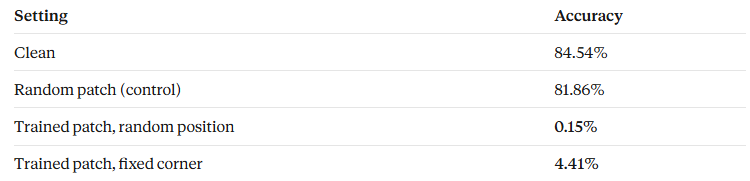

**The ASR is 99.88%:** of the 3,318 images the model got right, the patch flipped 3,314. The random-patch control moved slightly (82.27% before, 81.86% now). That’s the expected wobble from random positions, which is why papers often average over several runs.

**Why is the corner slightly weaker?** A likely reason is that pixels at the image edge are processed with zero-padding and fall inside fewer of the network’s overlapping receptive fields, so a patch there has a bit less influence. The patch still works almost everywhere, which confirms the EOT-style training did its job.

**Step 7: The TAPDreamer-style attack (feature-space loss with a hook)**

**What and why:** In step 5, the loss used the model’s **final answer**: push down the probability of the true label. That needs labels and the full model, all the way to the output.

TAPDreamer attacks a different place: **the hidden features in the middle of the network**. The goal is to make the network’s internal description of a patched image as different as possible from its description of the clean image. If the inner representation is scrambled, everything built on top of it, such as a classifier or a detection head, gets garbage.

**The loss becomes:**

**loss = −L1(features of patched image, features of clean image)**

**L1 distance** is the average absolute difference between two sets of numbers. For example, between [1, 4, 2] and [3, 1, 2], the differences are |1−3| = 2, |4−1| = 3 and |2−2| = 0, so the average is 5 ÷ 3 ≈ 1.67. The minus sign turns “maximise the distance” into something the optimiser can minimise, exactly as in step 5.

**Two things change compared with step 5:**

- **No labels are used.** The loss never looks at the true class. It only compares the clean and patched features. That makes it task-agnostic: you don’t need to know what the model is being used for.
- **We only the need the network up to the hidden layer.** This makes the attack useful when only a shared pretrained encoder is available.


**How we read hidden features: a forward hook.** PyTorch normally only gives you the model’s final output. A forward hook is a small function you attach to one layer. Every time that layer runs, PyTorch calls your function with the layer’s output, and you can save it. It’s like attaching a probe to one point inside the network without changing anything about how the network runs.

Here’s one training step. The clean and patched images go through the same frozen layers, the hook reads the features at layer 3, and the loss compares them:

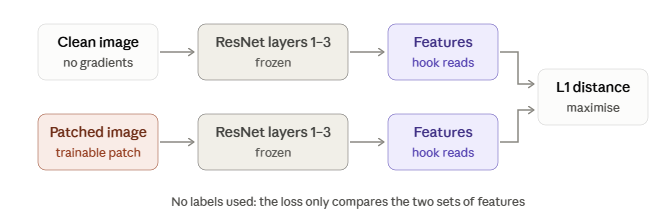

**7a. Attach the hook**

**The flow:**

1. Make an empty dictionary to hold the captured features.
2. Write the hook function, which saves whatever the layer outputs.
3. Attach it to layer3 of ResNet.
4. Test it on a few images and check the shape of what it captured.

In [ ]:
features = {}                                      # empty dictionary; the hook will store layer outputs here

# The hook function. PyTorch calls it automatically every time the hooked layer runs,
# and always passes it three things: the layer itself, the layer's input, and the layer's output.
def save_output(module, inputs, output):
    features["layer3"] = output                    # keep the output; we ignore module and inputs

# model       = our NormalisedModel wrapper (step 2b)
# model.model = the ResNet inside it
# .layer3     = ResNet's third block of layers (a mid-level layer)
# register_forward_hook attaches our function; it returns a "handle" we can use to remove it later.
hook_handle = model.model.layer3.register_forward_hook(save_output)

# Test the hook on 4 validation images.
check_images, _ = next(iter(val_loader))           # a fresh batch, in case Colab restarted
check_images = check_images[:4].to(device)         # keep just the first 4 images

with torch.no_grad():                              # just checking, no gradients needed
    _ = model(check_images)                        # a normal forward pass; "_" = we ignore the final output

# The hook ran during that forward pass and filled the dictionary.
print("Hooked feature shape:", features["layer3"].shape)   # expect [4, 1024, 14, 14]

Hooked feature shape: torch.Size([4, 1024, 14, 14])


**Where layer3 lives.** ResNet-50 is built from named parts in order: **conv1 → layer1 → layer2 → layer3 → layer4 → avgpool → fc**. You saw **fc**, the final 1,000-score layer, earlier. Because we wrapped ResNet in ***NormalisedModel***, the real ResNet is at ***model.model***, so the full path is ***model.model.layer3***.

**Why layer 3?** It’s a mid-level representation. Early layers detect edges and colours, which are too low-level: changing them is easy but doesn’t say much. Layer 4 is close to the classifier and very class-specific. Layer 3 encodes parts and textures, which is general enough that disrupting it should damage anything built on top. Comparing layers is a good extension once this works.

**The hook’s three arguments.** PyTorch decides what’s passed in: the layer object, its input and its output. Your function must accept all three, even though we only use ***output***.

The shape **[4, 1024, 14, 14]**. For each of the 4 images, layer 3 produces 1,024 feature maps (channels), each 14×14. Each channel is a detector for some pattern, and each of the 14×14 positions says how strongly that pattern appears in that region of the image. The 224-pixel image has been shrunk 16 times (224 ÷ 16 = 14), so each position summarises roughly a 16×16-pixel area. In total there are 1024 × 14 × 14 ≈ 200,000 numbers per image, and this is what our L1 loss compares.

**The handle**: ***hook_handle*** lets us detach the hook later with ***hook_handle.remove()***. Hooks stay attached until removed, so it’s good practice to clean them up when you’re done (7d).

**7b. Train a new patch with the feature loss**

**The flow. Almost identical to step 5. For each batch:**

1. Run the clean images through the model with no gradients, and grab the hooked features. This is the fixed reference.
2. Run the patched images through the model, and grab the hooked features.
3. Loss = −(L1 distance between the two).
4. zero_grad → backward → step → clamp, as before.
5. Record the distance and, for monitoring only, the misclassification rate.

In [ ]:
# A brand-new random patch, so this attack starts from scratch.
# The step-5 patch stays in `patch` and is saved in patch_ce.pt.
patch_feat = torch.rand(3, PATCH_SIZE, PATCH_SIZE, device=device, requires_grad=True)

optimizer_feat = torch.optim.Adam([patch_feat], lr=0.01)   # same optimiser settings as step 5, for a fair comparison
feat_loss_history = []                                     # loss after every update

for epoch in range(NUM_EPOCHS):                            # same 5 epochs as step 5
    epoch_dist = 0.0                                       # summed L1 distance this epoch
    fooled = 0                                             # misclassified images (monitoring only)
    seen = 0

    for images, labels in train_loader:
        images = images.to(device)
        targets = imagenet_idx.to(device)[labels.to(device)]   # NOT used in the loss, only to monitor misclassification

        # 1. Clean features: the reference we want to move AWAY from.
        #    no_grad: the clean image has no patch, so no gradients are needed here.
        with torch.no_grad():
            model(images)                                  # forward pass; the hook fills features["layer3"]
            clean_feat = features["layer3"]                # grab it NOW, before the next forward pass overwrites it

        # 2. Patched features: these DO need gradients, so they can flow back to the patch.
        logits = model(apply_patch(images, patch_feat))   # forward pass on patched images (random positions)
        patched_feat = features["layer3"]                  # the hook has overwritten the dict with the patched features

        # 3. L1 distance = mean absolute difference over all ~200k feature values per image, averaged over the batch.
        dist = F.l1_loss(patched_feat, clean_feat)
        loss = -dist                                       # maximise the distance -> minimise its negative

        # 4. The same three-line update as step 5, plus the clamp.
        optimizer_feat.zero_grad()
        loss.backward()
        optimizer_feat.step()
        with torch.no_grad():
            patch_feat.clamp_(0, 1)

        # 5. Bookkeeping.
        feat_loss_history.append(loss.item())
        epoch_dist += dist.item() * labels.size(0)
        fooled += (logits.argmax(dim=1) != targets).sum().item()
        seen += labels.size(0)

    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
          f"avg L1 feature distance: {epoch_dist / seen:.4f} | "
          f"training images misclassified: {fooled / seen:.2%}")

Epoch 1/5 | avg L1 feature distance: 0.0173 | training images misclassified: 20.90%
Epoch 2/5 | avg L1 feature distance: 0.0239 | training images misclassified: 31.30%
Epoch 3/5 | avg L1 feature distance: 0.0264 | training images misclassified: 40.50%
Epoch 4/5 | avg L1 feature distance: 0.0274 | training images misclassified: 44.40%
Epoch 5/5 | avg L1 feature distance: 0.0281 | training images misclassified: 46.55%


**Two forward passes per batch**. Each batch runs the model twice: once clean, once patched. The hook fires both times and overwrites ***features["layer3"]*** each time. That’s why we copy it into ***clean_feat*** *immediately* after the clean pass. If we waited until after the patched pass, both variables would hold the patched features, the distance would always be 0, and the patch would never learn. It’s a classic hook bug.

**Why the clean pass uses *no_grad*.** The clean features are a fixed target. We want to move the patched features away from them, not change them. No patch is involved in the clean pass, so there’s nothing to compute gradients for.

***F.l1_loss(patched_feat, clean_feat)*** takes every pair of matching numbers in the two feature tensors, computes the absolute difference, and averages over everything: about 200,000 values per image × 32 images. It’s the same idea as the **[1, 4, 2] vs [3, 1, 2]** example, just at scale.

**Labels are only used for monitoring.** ***targets*** appears only in the ***fooled*** count, never in the loss. Watch whether the misclassification rate rises even though the loss never asked for it. That’s the real test of whether disrupting features is enough to break the task.

**Same settings as step 5.** Patch size, learning rate, epochs, positions and data are all identical. Only the loss differs, so any difference in the results is caused by the objective. That’s the core of a controlled comparison.

**What to expect.** The printed L1 distance is positive and should grow every epoch, the mirror image of the negative loss falling.

**7c. Evaluate, and compare with step 5**

                                  Accuracy       ASR
Clean                               84.54%         -
Random patch (control)              81.86%         -
Cross-entropy patch (step 5)         0.15%    99.88%
Feature-L1 patch (step 7)           51.97%    39.39%

Most common predictions with the feature-L1 patch:
  tench                       304 images (7.7%)
  golf ball                   290 images (7.4%)
  parachute                   269 images (6.9%)
  French horn                 247 images (6.3%)
  soccer ball                 218 images (5.6%)


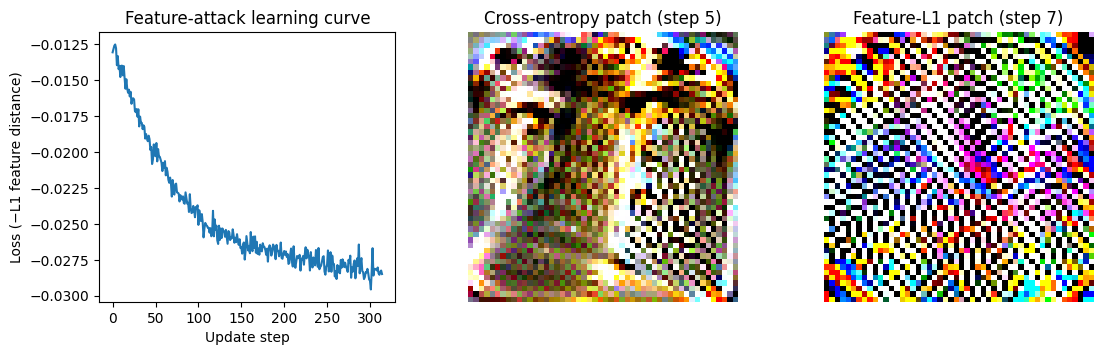

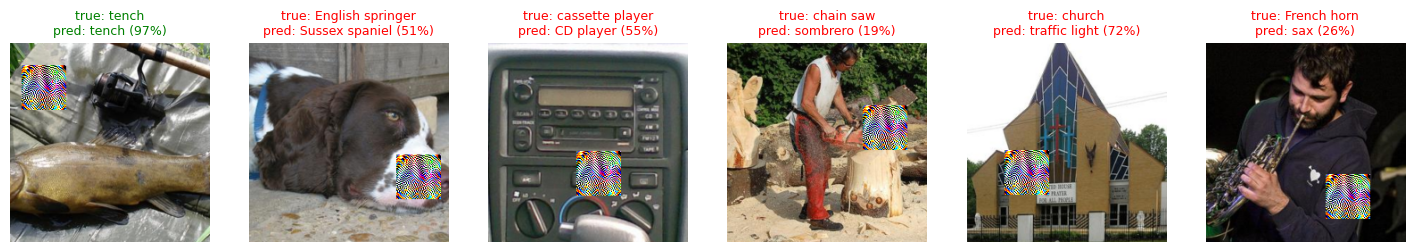

Saved trained patch to patch_feat.pt


In [ ]:
# Accuracy and ASR with the feature-loss patch, using the same functions as step 6.
add_feat_patch = lambda imgs: apply_patch(imgs, patch_feat)            # random positions

feat_acc = evaluate(model, val_loader, transform_fn=add_feat_patch)
feat_preds = predicted_classes(model, val_loader, add_feat_patch)
feat_flipped = clean_correct & (feat_preds != all_targets)             # right when clean, wrong with this patch
feat_asr = feat_flipped.sum().item() / clean_correct.sum().item()

# Side-by-side comparison.
print(f"{'':32}{'Accuracy':>10}{'ASR':>10}")
print(f"{'Clean':32}{clean_acc:>10.2%}{'-':>10}")
print(f"{'Random patch (control)':32}{random_patch_acc:>10.2%}{'-':>10}")
print(f"{'Cross-entropy patch (step 5)':32}{trained_acc:>10.2%}{asr:>10.2%}")
print(f"{'Feature-L1 patch (step 7)':32}{feat_acc:>10.2%}{feat_asr:>10.2%}")

# What does the model predict now? Same counting as 6c.
feat_counts = torch.bincount(feat_preds, minlength=1000)
top_counts, top_classes = feat_counts.topk(5)
print("\nMost common predictions with the feature-L1 patch:")
for c, n in zip(top_classes, top_counts):
    print(f"  {categories[c]:<25} {n.item():>5} images ({n.item() / len(feat_preds):.1%})")

# The two learned patches side by side, plus the feature-attack learning curve.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(feat_loss_history)
axes[0].set_xlabel("Update step")
axes[0].set_ylabel("Loss (−L1 feature distance)")
axes[0].set_title("Feature-attack learning curve")
axes[1].imshow(patch.detach().cpu().permute(1, 2, 0))
axes[1].set_title("Cross-entropy patch (step 5)")
axes[1].axis("off")
axes[2].imshow(patch_feat.detach().cpu().permute(1, 2, 0))
axes[2].set_title("Feature-L1 patch (step 7)")
axes[2].axis("off")
plt.show()

# The six example images with the new patch.
show_predictions(model, val_set, sample_idx, transform_fn=add_feat_patch)

# Save the new patch alongside the first one.
torch.save(patch_feat.detach().cpu(), "patch_feat.pt")
print("Saved trained patch to patch_feat.pt")

**Everything is reused**. ***evaluate***, ***predicted_classes***, ***show_predictions***, ***clean_correct*** and ***all_targets*** all come from steps 3 and 6. Only the patch changes. This is why we built general-purpose functions early on: comparing a new attack now takes a few lines.

**The formatting codes.** ***:32*** pads text to 32 characters, and ***:>10.2%*** right-aligns a percentage in 10 characters, so the table columns line up. It’s purely cosmetic.

**What to look for:**

- **ASR.** Is the feature attack as strong as the cross-entropy attack, or weaker?

- **The prediction spread.** Does it collapse onto one class like “thimble”, or scatter? A label-free objective has no reason to favour a single class, so scattered predictions would show the patch is breaking the representation rather than hijacking it.

- **The patches themselves.** Do they look alike, or is the feature patch a different kind of pattern?

**7d. Remove the hook**

In [ ]:
hook_handle.remove()        # detach the hook from layer3; the model is back to normal
print("Hook removed.")

Hook removed.


Hooks stay attached until removed and fire on every forward pass, including ones where you don’t want them. Removing it when you’re done avoids confusing bugs later, such as a stale **features** dict or extra memory use.

**RESULTS FROM STEP 7C:**

We trained an adversarial patch against a pretrained torchvision ResNet, then swapped in the TAPDreamer-style objective (maximising L1 feature distance at a hidden layer, read out with a forward hook). Both attacks work, and because everything except the loss was held fixed, the comparison is a fair one.

**The headline numbers:**

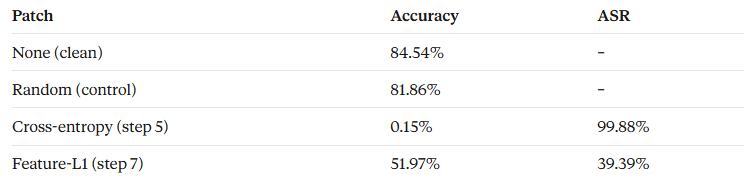

The feature attack is clearly real. Random noise costs about 3 points of accuracy, while the feature patch costs about 33 points, and it achieved that **without ever seeing a label**. But it’s much weaker than the cross-entropy attack.

**Break vs hijack**:

Read the top-5 list carefully. Tench, golf ball, parachute and French horn are four of the ten true Imagenette classes. Those counts are mostly the ~52% of images the model still gets right. No wrong class dominates. Compare that with 99.9% “thimble” in step 5.

**The six example images show what the errors look like:**

- English springer → Sussex spaniel
- Cassette player → CD player
- French horn → sax
- Chain saw → sombrero (only 19% confident)

Most mistakes are **near-misses to similar classes**, often at low confidence. So the two patches behave very differently:

- **The cross-entropy patch hijacks.** It forces one specific wrong answer, with 100% confidence, everywhere.
- **The feature patch breaks.** It degrades the internal representation enough that the model slides to a nearby class, but it doesn’t steer it anywhere in particular.

That makes sense: the feature loss only says "be different from clean", never "be this".

**The learning curve and the patch**:

The curve is smooth, with no plateau-then-takeoff like step 5, and **it is still going down at step 315**. The feature distance grew from 0.0173 to 0.0281 and hadn’t levelled off, so more epochs would likely make the attack stronger. The cross-entropy curve, by contrast, had flattened.

The patches look completely different. The cross-entropy patch has object-like structure, which ended up as a thimble. The feature patch is a fine, saturated, high-frequency stripe and checker pattern. That suggests the optimiser found that sharp, high-contrast texture is the most efficient way to make many of layer 3’s 1,024 detectors fire differently, rather than imitating any object.

**Why is the feature attack weaker?**

A likely reason is **dilution**. The patch covers about 5% of the image, but the L1 loss averages over all 14×14 spatial positions of layer 3’s output. Most of those positions still describe clean image content, and the rest of the network (layer 4, then average pooling over the whole image) still has plenty of intact evidence to work with. The cross-entropy loss has no such problem, because it targets the final decision directly.

**The patch is saved as .pt file (PyTorch File)**: It stores the tensor’s raw numbers (here 3×50×50 pixel values), not an image. Your computer has no app that opens it on double-click. You load it back with PyTorch.

**To get a viewable image as well:**
If you want something you can open normally, also save the patches as PNGs.

In [ ]:
import torch.nn.functional as F
from torchvision.utils import save_image

# The patches are only 50x50 pixels, tiny on screen. Enlarge them 10x to 500x500.
# mode="nearest" copies each pixel into a 10x10 block, so the pattern stays sharp instead of blurred.
# unsqueeze(0) adds a batch dimension, (3, 50, 50) -> (1, 3, 50, 50), because interpolate expects a batch.
big_ce = F.interpolate(patch.detach().cpu().unsqueeze(0), scale_factor=10, mode="nearest")
big_feat = F.interpolate(patch_feat.detach().cpu().unsqueeze(0), scale_factor=10, mode="nearest")

save_image(big_ce, "patch_ce.png")        # save_image expects values in [0, 1], which the clamp guaranteed
save_image(big_feat, "patch_feat.png")
print("Saved patch_ce.png and patch_feat.png")

Saved patch_ce.png and patch_feat.png
